In [50]:
import matplotlib.pyplot as plt
from PIL import Image
from brokenaxes import BrokenAxes
from intervaltree import Interval, IntervalTree
import numpy as np
import os
import random
import matplotlib.cm as cm
import argparse
import pandas as pd
import subprocess
import shutil
import seaborn as sns
from collections import deque


def merge_intervals(intervals):
    """Merge overlapping x-axis intervals using IntervalTree."""
    tree = IntervalTree(Interval(start, end) for start, end in intervals)
    #merge overlapping intervals
    tree.merge_overlaps() 
    #return list (not tuple) 
    return sorted((iv.begin, iv.end) for iv in tree)

def plot_multiple_datasets(dataset_list, name_list, output_folder, run_number):
    """
    Draw n subgraphs using the structure of 'original'.
    Each subplot shows only colored matches for that dataset.
    The bottom subplot is the full 'original' dataset in black.
    """
    if "original" not in name_list:
        raise ValueError("You must include 'original' in name_list")

    original_idx = name_list.index("original")
    original_dataset = dataset_list[original_idx]

    #add back original at the end
    all_names = name_list
    all_datasets = dataset_list

    n = len(all_datasets)
    fig, axes = plt.subplots(n, 1, figsize=(12, 3 * n), sharex=True, sharey=True)

    if n == 1:
        axes = [axes]

    global_max_x = max(e for block in original_dataset for (s, e, _) in block)
    global_max_y = max(c for block in original_dataset for (_, _, c) in block) * 2

    #cmap = cm.get_cmap('tab10', sum(len(sublist) for sublist in all_datasets))
    # cmap = plt.cm.get_cmap('tab20', 200)
    N = 100
    colors = sns.color_palette("hls", N)
    step = N // 10  
    reordered_colors = [colors[(i * step) % N] for i in range(N)]
    # cmap = plt.cm.get_cmap('viridis', sum(len(sublist) for sublist in all_datasets))

    for idx, (ax, label, data) in enumerate(zip(axes, all_names, all_datasets)):
        # color = 'black' if label == "original" else cmap(idx)
        # color = 'black'
        # overlay_set = set((s_sub, e_sub, c_sub_block) for block in data for (s_sub, e_sub, c_sub_block) in block)
        # overlay_dict = {i: (s_sub, e_sub, c_sub_block) for i, (s_sub, e_sub, c_sub_block) in enumerate(overlay_set)}
        # print("idx",idx)
        # print(overlay_dict)
        # color = cmap(idx)
        for block_index, original_block in enumerate(original_dataset):
            important_ranges = [(s, e) for s, e, _ in original_block]
            merged_xlims = merge_intervals(important_ranges)
            distance = 0
            
            # print("original block_index")
            # print(block_index)
            # print("original block")
            # print(original_block)
            for s, e, c in original_block:
                if merged_xlims and s == merged_xlims[0][0]:
                    distance = 0
                    merged_xlims.pop(0)

                # For overlay: draw only if matched
                if label == "original": 
                    # color = cmap(block_index)
                    y_pos = [distance + i + 1 for i in range(c)]
                    for y in y_pos:
                        ax.hlines(y, s, e, colors=reordered_colors[block_index], linewidth=1.8)
                    distance = y_pos[-1]
                else:
                    for sub_id, sub_block in enumerate(data):
                        s_sub_block = min(s for (s, e, _) in sub_block)
                        e_sub_block = max(e for (s, e, _) in sub_block)
                        if s >= s_sub_block and e <= e_sub_block:
                            # color = cmap(sub_id)
                            y_pos = [distance + i + 1 for i in range(c)]
                            for y in y_pos:
                                # print("s,e,c,color,sub_id,label")
                                # print(s,e,c,reordered_colors[sub_id],sub_id,label)
                                ax.hlines(y, s, e, colors=reordered_colors[sub_id], linewidth=1.8)
                            distance = y_pos[-1]

        ax.set_title(label)
        ax.set_xlim(0, global_max_x + 10)
        ax.set_ylim(0, global_max_y + 5)
        ax.set_ylabel("Coverage")
        ax.grid(True, axis='x', linestyle='--', alpha=0.5)

    axes[-1].set_xlabel("Genome Position")
    plt.tight_layout()
    plt.savefig(f"{output_folder}/simulation_final_blocks_{run_number}.png", dpi=300, bbox_inches='tight')
    plt.close()

##function to plot each dataset
# def plot_dataset(dataset, name, output_folder):
#     num_blocks = len(dataset)
#     cmap = cm.get_cmap('tab20', num_blocks)
#     fig, ax = plt.subplots(figsize=(12, 4))
#     for block_index, block in enumerate(dataset):
#         x_min = min(int(item[0]) for item in block)
#         x_max = max(int(item[1]) for item in block)
#         #print(f"Dataset {dataset_idx}: xlim = ({x_min}, {x_max})")
#         parameter = 1
#         # Step 1: Create unique x-limits based on dataset
#         important_ranges = []
#         important_ranges = [(start, end) for start, end, _ in block]
#         merged_xlims = merge_intervals(important_ranges)
#         # print(merged_xlims)
#         # Step 3: Plot horizontal lines
#         distance = 0
#         color = cmap(block_index)
#         for start, end, line_count in block:
#             # print(start,end,line_count)
#             if merged_xlims and int(start) == merged_xlims[0][0]:
#                 # logging.info("start")
#                 # logging.info(start)
#                 distance = 0
#                 merged_xlims.pop(0)
#             y_positions = [distance + parameter * (i + 1) for i in range(int(line_count))]
#             # print(y_positions)
#             # random_color = np.random.rand(3,)
#             for y in y_positions:
#                 plt.hlines(y, start, end, colors=color, linestyles='solid', linewidth=1)
#             distance = y_positions[-1]
            

#     ax.set_xlabel("Genome Position")
#     ax.set_ylabel("Coverage")    
#     # plt.show()

#     #save the plot to a buffer as a grayscale image
#     buffer_path = f"{output_folder}/simulation_1_20_gaps_{name}_blocks.png"
#     plt.savefig(buffer_path, format='png', dpi=300, bbox_inches='tight')
#     plt.close()

                    
# def collect_all_blocks_data(simulation_data_folder, files):
#     bed_blocks = {}
#     block_lines = []
#     # print(files)
#     for file_name in files:
#         try:
#             file_path = os.path.join(simulation_data_folder, file_name)
#             with open(file_path, "r") as file:
#                 bed_blocks[file_name] = []
#                 chrom_blocks = []
#                 line_block = []
#                 collecting = False
#                 for line in file:
#                     line = line.strip()
#                     if line == "":
#                         collecting = False
#                         if line_block:
#                             bed_blocks[file_name].append(line_block)
#                             line_block = []
#                     elif line == "original bed lines:":
#                         collecting = True
#                     elif collecting:
#                         columns = line.split('\t')
#                         line_block.append([columns[0],columns[1],columns[2],columns[3], columns[4], columns[5], columns[6]])
#         except Exception as e:
#             print(f"Error opening file '{file_path.get(file_name, 'UNKNOWN')}': {e}")

#     return bed_blocks

def collect_all_blocks_data(simulation_data_folder, files):
    bed_blocks = {}
    for file_name in files:
        file_path = os.path.join(simulation_data_folder, file_name)
        bed_blocks[file_name] = []
        try:
            with open(file_path, "r") as file:
                line_block = []
                collecting = False
                for line in file:
                    line = line.strip()
                    if line == "":
                        collecting = False
                        if line_block:
                            if "partial" in file_path:
                                intervals = sorted([(int(x[1]), int(x[2])) for x in line_block])
                                min_start, max_end = intervals[0][0], intervals[-1][1]

                                coverage = set()
                                for start, end in intervals:
                                    coverage.update(range(start, end))

                                if coverage == set(range(min_start, max_end)):
                                    bed_blocks[file_name].append(line_block)
                            else:
                                bed_blocks[file_name].append(line_block)

                            line_block = []
                    elif line == "original bed lines:":
                        collecting = True
                        line_block = []
                    elif collecting:
                        columns = line.split('\t')
                        line_block.append([columns[0],columns[1],columns[2],columns[3], columns[4], columns[5], columns[6]])
            # # Final check after file ends
            # if line_block:
            #     if "partial" in file_path:
            #         intervals = sorted([(int(x[1]), int(x[2])) for x in line_block])
            #         min_start, max_end = intervals[0][0], intervals[-1][1]

            #         coverage = set()
            #         for start, end in intervals:
            #             coverage.update(range(start, end))

            #         if coverage == set(range(min_start, max_end)):
            #             bed_blocks[file_name].append(line_block)
            #     else:
            #         bed_blocks[file_name].append(line_block)

        except Exception as e:
            print(f"Error opening file '{file_path}': {e}")

    return bed_blocks


def cluster_blocks_by_chrom(bed_blocks, files):
    group_all = {}
    for file_name in files:
        group = {}
        # group[chrom] = []
        group_all[file_name] = {}
        for block in bed_blocks[file_name]:
            chrom = block[0][0]
            if chrom not in group:
                group[chrom] = []
            group[chrom].append(block)
        group_all[file_name] = group
    return group_all

def simulate_data_generation(original_data, blocks_number, start_point, file_name, seq_id_dataset):
    # print("start original data")
    # print(original_data)
    # print("end original data")

    # print("file_name")
    # print(file_name)
    file_id = 0
    if "symmetric" in file_name:
        file_id = 1
    elif "fully_overlap" in file_name:
        file_id = 2
    elif "partial" in file_name:
        file_id = 3
    elif "singleton" in file_name:
        file_id = 4

    #need to delete this block when finished using.
    random_block_id = random.randint(0, blocks_number - 1)
    original_min_start_point = min(int(line[1]) for line in original_data[random_block_id])
    original_max_end_point = max(int(line[2]) for line in original_data[random_block_id])
    move_units = original_min_start_point - start_point
    max_end_point = original_max_end_point - move_units
    whole_block_data = []
    whole_block_simple_data = []
    block_data = []

    for line in original_data[random_block_id]:
        line_start = int(line[1])
        line_end = int(line[2])
        line_count = int(line[6])
        # print(line[1],line[2],line[3],min_start_point)
        count = 50 if line_count > 50 else line_count
        # print(line_start - min_start_point, line_end - min_start_point, count)
        current_seq_id = seq_id_dataset.popleft() 
        whole_block_data.append([line[0], line_start - move_units, line_end - move_units, line[3], current_seq_id, current_seq_id, count, file_id])
        whole_block_simple_data.append([line[0], line_start - move_units, line_end - move_units, count, file_id])
        block_data.append([line_start - move_units, line_end - move_units, count])
    # print("aaa")
    ###modify0605
    # original_data.remove(original_data[random_block_id])
    return block_data, whole_block_data, whole_block_simple_data, max_end_point

def generate_all_data(bed_blocks_group_by_chrom, files, blocks_number, smallest_gap, biggest_gap, seq_id_dataset):
    number = 0
    dataset = []
    whole_dataset = {}
    whole_simplify_data = {}
    random_file = random.choice(files)
    random_chrom = random.choice(list(bed_blocks_group_by_chrom[random_file].keys()))
    start_point = 1 
    while number < blocks_number:
        random_file = random.choice(files)
        actual_blocks_number = len(bed_blocks_group_by_chrom[random_file][random_chrom])
        block_data, whole_block_data, whole_simple_block_data, end_point = simulate_data_generation(bed_blocks_group_by_chrom[random_file][random_chrom], actual_blocks_number, start_point, random_file, seq_id_dataset)
        dataset.append(block_data)
        whole_dataset[number] = whole_block_data
        whole_simplify_data[number] = whole_simple_block_data
        # print("whole_block_data", whole_block_data)
        start_point = end_point + random.randint(smallest_gap, biggest_gap)
        number += 1
    return dataset,whole_dataset,whole_simplify_data

def create_bed_file(result, bed_file_path):
    data = []
    for value_lists in result.values():
        # print("value_lists",value_lists)
        # for sublist in value_lists:
        data.extend(value_lists)
    # print("data:",data)
    df = pd.DataFrame(data, columns=['chrome', 'start', 'end','sequence','id','same_ids','same_seq_count','file_id'])
    # df['chrome'] = "NZ_LR134354.1"
    df.sort_values(by=['chrome', 'start', 'end'], ascending=[True, True, True], inplace=True)
    sorted_data = []
    sorted_data = df.values.tolist()

    # write data to the bed file
    with open(bed_file_path, "w") as file:
        for line in sorted_data:
            file.write("\t".join(map(str, line[:-1])) + "\n")

def clean_folder(folder_path):
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        try:
            if os.path.isfile(file_path) or os.path.islink(file_path):
                os.unlink(file_path)  # remove file or symlink
            elif os.path.isdir(file_path):
                shutil.rmtree(file_path)  # remove folder and all its contents
        except Exception as e:
            print(f'Failed to delete {file_path}. Reason: {e}')

def run_simulation_code(code_folder, bed_file_path, output_folder):
    ##run additonal step
    clean_folder(os.path.join(output_folder,"results"))
    script_path = os.path.join(code_folder, "classify_mapping_patterns.py")
    
    command = [
        "python3", script_path,
        "-input_bedfile", bed_file_path,
        "-output_folder", os.path.join(output_folder,"results")
    ]

    subprocess.run(command, check=True)

def normalize_id(s):
    return '|'.join(sorted(s.split('|')))

# def new_simulation_redecide_class(output_folder):
#     df_new_blocks = pd.read_csv(os.path.join(output_folder, "results","final_all_blocks_table.csv"),sep = ",")
#     df_new_blocks['normalized_id'] = df_new_blocks['representative_SeqID'].apply(normalize_id)
#     df['combined_label'] = ''
#     #compare every row
#     for i in range(len(df)):
#         id_i = df.loc[i, 'normalized_id']
#         combined =[]
#         combined.append(df.loc[i, 'dataset_type'])

#         for j in range(len(df)):
#             if i == j:
#                 continue
#             id_j = df.loc[j, 'normalized_id']
#             if id_i.issubset(id_j):
#                 combined.append(df.loc[j, 'dataset_type'])

#         if combined:
#             df.at[i, 'combined_label'] = ','.join(combined)
def get_df_old_blocks(result):
   #['chrome', 'start', 'end','sequence','id','same_ids','same_seq_count','file_id'])
    data =[]
    for key, value in result.items():
        start = [lst[1] for lst in value]
        end = [lst[2] for lst in value]
        data_type = value[0][-1] 
        min_start = min(start)
        max_end = max(end)
        data.append([min_start,max_end,data_type])
    df = pd.DataFrame(data, columns=['start','end','dataset_type'])
    return df
        # for sublist in value_lists:
        # data.extend(value_lists)
    # print("data:",data)


# Step 1: keep only one interval among the intervals which have same start and end, and merge dataset_type
def merge_duplicates(df):
    df = df.copy()
    df.loc[:, 'min_start'] = df['start'].apply(lambda x: min(map(int, str(x).split('|'))))
    df.loc[:, 'max_end'] = df['end'].apply(lambda x: max(map(int, str(x).split('|'))))
    df['dataset_type'] = df['dataset_type'].astype(str)

    grouped = df.groupby(['min_start', 'max_end'])['dataset_type'].apply(
        lambda x: '|'.join(sorted(set('|'.join(x).split('|')))
    )).reset_index()
    grouped = grouped.rename(columns={'min_start': 'start', 'max_end': 'end'})
    # print("grouped:")
    # print(grouped)
    return grouped

# # Step 3: For each largest block, recursively process based on subintervals
# def split_by_priority(start, end, sub_parts):
#     result = []
#     i = 0
#     while i < len(sub_parts):
#         part = sub_parts[i]
#         if part['start'] < start or part['end'] > end:
#             i += 1
#             continue

#         types = set(part['dataset_type'].split('|'))

#         if '1' in types:
#             # Collect all connected type=1 blocks
#             group_start = part['start']
#             group_end = part['end']
#             i += 1
#             while i < len(sub_parts):
#                 next_types = set(sub_parts[i]['dataset_type'].split('|'))
#                 if '1' in next_types and sub_parts[i]['start'] == group_end:
#                     group_end = sub_parts[i]['end']
#                     i += 1
#                 else:
#                     break
#             result.append({'start': group_start, 'end': group_end, 'dataset_type': '1'})
#             start = group_end  # move pointer
#         elif '2' in types:
#             group_start = part['start']
#             group_end = part['end']
#             i += 1
#             while i < len(sub_parts):
#                 next_types = set(sub_parts[i]['dataset_type'].split('|'))
#                 if '2' in next_types and sub_parts[i]['start'] == group_end:
#                     group_end = sub_parts[i]['end']
#                     i += 1
#                 else:
#                     break
#             result.append({'start': group_start, 'end': group_end, 'dataset_type': '2'})
#             start = group_end
#         elif '4' in types:
#             group_start = part['start']
#             group_end = part['end']
#             i += 1
#             while i < len(sub_parts):
#                 next_types = set(sub_parts[i]['dataset_type'].split('|'))
#                 if '4' in next_types and sub_parts[i]['start'] == group_end:
#                     group_end = sub_parts[i]['end']
#                     i += 1
#                 else:
#                     break
#             result.append({'start': group_start, 'end': group_end, 'dataset_type': '4'})
#             start = group_end
#         else:
#             result.append(part)
#             i += 1

#     return result
    
# # Step 2: remove subset intervals and merge dataset_type
# def filter_new_blocks_with_bigger_length_priority(df):
#     df = df.copy()

#     # Step 1: Keep only largest blocks (remove nested)
#     df = df.sort_values(by=['start', 'end'], ascending=[True, False]).reset_index(drop=True)
#     largest_blocks = []
#     for _, row in df.iterrows():
#         s, e = row['start'], row['end']
#         is_subset = False
#         for existing in largest_blocks:
#             if s >= existing['start'] and e <= existing['end']:
#                 is_subset = True
#                 break
#         if not is_subset:
#             largest_blocks.append(row)
#     df_largest = pd.DataFrame(largest_blocks)

#     # Step 2: Build sub-intervals from original df
#     points = sorted(set(df['start']).union(set(df['end'])))
#     sub_intervals = []
#     for i in range(len(points) - 1):
#         sub_start, sub_end = points[i], points[i + 1]
#         overlaps = df[(df['start'] <= sub_start) & (df['end'] >= sub_end)]
#         if not overlaps.empty:
#             all_types = overlaps['dataset_type'].apply(lambda x: x.split('|'))
#             flat = [t for group in all_types for t in group]
#             merged_type = '|'.join(sorted(set(flat)))
#             sub_intervals.append({'start': sub_start, 'end': sub_end, 'dataset_type': merged_type})
#     final_result = []
#     for _, block in df_largest.iterrows():
#         s, e = block['start'], block['end']
#         inside_parts = [sub for sub in sub_intervals if sub['start'] >= s and sub['end'] <= e]
#         final_result.extend(split_by_priority(s, e, inside_parts))

#     return pd.DataFrame(final_result).sort_values(by=['start', 'end']).reset_index(drop=True)

##wrong
# def explode_intervals(df):
#     # 1. Get all unique start and end positions
#     points = sorted(set(df['start']).union(set(df['end'])))
    
#     # 2. Generate all sub-intervals
#     sub_intervals = []
#     for i in range(len(points) - 1):
#         sub_start = points[i]
#         sub_end = points[i + 1]

#         # 3. Find all original intervals that overlap this sub-interval
#         overlaps = df[(df['start'] <= sub_start) & (df['end'] >= sub_end)]
#         if not overlaps.empty:
#             all_types = overlaps['dataset_type'].apply(lambda x: x.split('|'))
#             flat_types = [t for sublist in all_types for t in sublist]
#             merged_type = '|'.join(sorted(set(flat_types)))
#             sub_intervals.append({'start': sub_start, 'end': sub_end, 'dataset_type': merged_type})

#     return pd.DataFrame(sub_intervals)
# def filter_blocks_with_special_3_handling(df):
#     df = df.copy()
#     df = df.sort_values(by=['start', 'end'], ascending=[True, False]).reset_index(drop=True)

#     merged_blocks = []

#     for _, row in df.iterrows():
#         # Check if current row is fully contained in the last merged one
#         if merged_blocks:
#             last = merged_blocks[-1]
#             if row['start'] >= last['start'] and row['end'] <= last['end']:
#                 combined_type = '|'.join(sorted(set(last['dataset_type'].split('|') + row['dataset_type'].split('|'))))
#                 merged_blocks[-1]['dataset_type'] = combined_type
#                 continue
#         merged_blocks.append(row)

#     merged_df = pd.DataFrame(merged_blocks)

#     # Separate out blocks of type 3
#     type3_blocks = merged_df[merged_df['dataset_type'] == '3']
#     other_blocks = merged_df[merged_df['dataset_type'].isin(['1', '2', '4'])]

#     # Get all cut points
#     points = sorted(set(merged_df['start']).union(set(merged_df['end'])))
#     sub_intervals = []

#     for i in range(len(points) - 1):
#         sub_start = points[i]
#         sub_end = points[i + 1]

#         # Check if any type-3 block covers this
#         overlapping_3 = type3_blocks[(type3_blocks['start'] <= sub_start) & (type3_blocks['end'] >= sub_end)]
#         if not overlapping_3.empty:
#             # Check what other blocks overlap this subregion
#             overlaps = merged_df[(merged_df['start'] <= sub_start) & (merged_df['end'] >= sub_end)]
#             types = [t for sublist in overlaps['dataset_type'].str.split('|') for t in sublist]
#             unique_types = sorted(set(types))
#             type_str = '|'.join(unique_types)
#             sub_intervals.append({'start': sub_start, 'end': sub_end, 'dataset_type': type_str})

#         # Special filter for sub-intervals
#         final_result = []
#         seen_2 = False
#         for interval in sub_intervals:
#             types = set(interval['dataset_type'].split('|'))
#             if '2' in types:
#                 seen_2 = True
#                 final_result.append(interval)
#             elif seen_2 and ('1' in types or '4' in types):
#                 final_result.append(interval)
#     # final_result = []
#     # seen_priority = 0  # Track the highest priority seen so far (1 is highest)
#     # priority_map = {'1': 1, '2': 2, '4': 3, '3': 4}

#     # for interval in sub_intervals:
#     #     types = set(interval['dataset_type'].split('|'))
#     #     min_type = min([priority_map[t] for t in types if t in priority_map])

#     #     if min_type < seen_priority or seen_priority == 0:
#     #         # Update seen_priority to the highest seen so far
#     #         seen_priority = min(seen_priority, min_type) if seen_priority else min_type

#     #     # Keep this interval only if its type has equal or higher priority
#     #     if min_type <= seen_priority:
#     #         final_result.append(interval)

#         # Combine with original type 1, 2, 4 blocks
#         final_df = pd.concat([other_blocks, pd.DataFrame(final_result)], ignore_index=True)
#         final_df = final_df.sort_values(by=['start', 'end']).reset_index(drop=True)
#         return final_df

#CORRECT,based on the longest seperation
def filter_new_blocks_with_bigger_length_priority(df):
    df = df.copy()
    # df['length'] = df['end'] - df['start']
    # Sort so outer blocks come first (start asc, end desc)
    df = df.sort_values(by=['start', 'end'], ascending=[True, False]).reset_index(drop=True)

    merged_blocks = []
    for _, row in df.iterrows():
        if not merged_blocks:
            merged_blocks.append(row)
        else:
            last = merged_blocks[-1]
            if row['start'] >= last['start'] and row['end'] <= last['end']:
                # Row is subset → merge dataset_type into last
                combined_type = '|'.join(sorted(set(last['dataset_type'].split('|') + row['dataset_type'].split('|'))))
                merged_blocks[-1]['dataset_type'] = combined_type
            # elif last['start'] >= row['start'] and last['end'] <= row['end']:
            #     # Last is subset → merge and replace with current row
            #     combined_type = '|'.join(sorted(set(last['dataset_type'].split('|') + row['dataset_type'].split('|'))))
            #     row['dataset_type'] = combined_type
            #     merged_blocks[-1] = row
            else:
                merged_blocks.append(row)

    result_df = pd.DataFrame(merged_blocks)
    return result_df

# def filter_new_blocks_with_bigger_length_priority(df):
#     df = df.sort_values(by=['start', 'end']).reset_index(drop=True)
#     merge = True
#     while merge:
#         merge = False
#         rows_to_drop = []
#         for i in range(len(df)):
#             s1, e1, t1 = df.loc[i, 'start'], df.loc[i, 'end'], df.loc[i, 'dataset_type']
#             for j in range(i+1, len(df)):
#                 s2, e2, t2 = df.loc[j, 'start'], df.loc[j, 'end'], df.loc[j, 'dataset_type']
#                 # if e1 < s2:
#                 #     continue
#                 if s1 >= s2 and e1 <= e2:
#                     # Merge types if it's a subset
#                     merged_type = '|'.join(sorted(set(t1.split('|') + t2.split('|'))))
#                     df.at[j, 'dataset_type'] = merged_type
#                     rows_to_drop.append(i)
#                     merge = True
#                     break
#                 elif s2 >= s1 and e2 <= e1:
#                     merged_type = '|'.join(sorted(set(t1.split('|') + t2.split('|'))))
#                     df.at[i, 'dataset_type'] = merged_type
#                     rows_to_drop.append(j)
#                     merge = True
#                     break
#             if merge:
#                 # print("df before")
#                 # print(df)
#                 # drop the rows
#                 df = df.drop(index=rows_to_drop).reset_index(drop=True)
#                 # print("df_after")
#                 # print(df)
#                 break
#     return df

# # Step 3: cut overlapping intervals and merge dataset_type
# def flatten_intervals(df):
#     df = df.sort_values(by=['start', 'end']).reset_index(drop=True)
#     queue = deque(df.to_dict('records'))
#     result = []

#     while queue:
#         current = queue.popleft()
#         has_overlap = False

#         for i in range(len(queue)):
#             compare = queue[i]

#             # Check for overlap
#             if current['end'] < compare['start'] or current['start'] > compare['end']:
#                 continue

#             has_overlap = True
#             overlap_start = max(current['start'], compare['start'])
#             overlap_end = min(current['end'], compare['end'])
#             merged_type = '|'.join(sorted(set(current['dataset_type'].split('|') + compare['dataset_type'].split('|'))))

#             # Generate new non-overlapping parts
#             new_parts = []
#             if current['start'] < overlap_start:
#                 new_parts.append({'start': current['start'], 'end': overlap_start, 'dataset_type': current['dataset_type']})

#             # if compare['start'] < overlap_start:
#             #     new_parts.append({'start': compare['start'], 'end': overlap_start, 'dataset_type': compare['dataset_type']})

#             # Overlapping part with merged type
#             new_parts.append({'start': overlap_start, 'end': overlap_end, 'dataset_type': merged_type})

#             # if current['end'] > overlap_end:
#             #     new_parts.append({'start': overlap_end, 'end': current['end'], 'dataset_type': current['dataset_type']})
#             if compare['end'] > overlap_end:
#                 new_parts.append({'start': overlap_end, 'end': compare['end'], 'dataset_type': compare['dataset_type']})

#             # Replace both entries with new parts
#             del queue[i]
#             queue.extendleft(reversed(new_parts))  # Maintain order
#             break

#         if not has_overlap:
#             result.append(current)

#     return pd.DataFrame(result).sort_values(by=['start', 'end']).reset_index(drop=True)

    # df = df.sort_values(by=['start', 'end']).reset_index(drop=True)
    # pick_i = 0
    # pick_j = 0
    # # rows_to_drop = []
    # overlap = True
    # while overlap:
    #     print("while")
    #     overlap = False
    #     # df = df.sort_values(by=['start', 'end']).reset_index(drop=True)
    #     new_rows = []
    #     df = df.drop(index=[pick_i, pick_j]).reset_index(drop=True)
    #     df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
    #     df = df.sort_values(by=['start', 'end']).reset_index(drop=True)
    #     print(df)
    #     for i in range(len(df)):
    #         s1, e1, t1 = df.loc[i, 'start'], df.loc[i, 'end'], df.loc[i, 'dataset_type']
    #         for j in range(i + 1, len(df)):
    #             s2, e2, t2 = df.loc[j, 'start'], df.loc[j, 'end'], df.loc[j, 'dataset_type']
    #             # if (e2 > s1) & (s2 < e1)
    #             # else:
    #             #     continue
    #             # Skip if no overlap
    #             if e1 < s2 or s1 > e2:
    #                 continue
    #             print("have overlap issues")
    #             # # There's an overlap, compute overlap segment
    #             overlap_start = max(s1, s2)
    #             overlap_end = min(e1, e2)
    #             # # Create combined type
    #             merged_type = '|'.join(sorted(set(t1.split('|') + t2.split('|'))))
                
    #             # new_rows = []

    #             if s1 < overlap_start:
    #                 new_rows.append({'start': s1, 'end': overlap_start, 'dataset_type': t1})

    #             if e1 > overlap_end:
    #                 new_rows.append({'start': overlap_end, 'end': e1, 'dataset_type': t1})

    #             if s2 < overlap_start:
    #                 new_rows.append({'start': s2, 'end': overlap_start, 'dataset_type': t2})

    #             if e2 > overlap_end:
    #                 new_rows.append({'start': overlap_end, 'end': e2, 'dataset_type': t2})

    #             new_rows.append({'start': overlap_start, 'end': overlap_end, 'dataset_type': merged_type})

    #             # Drop the original rows and restart loop
    #             # df = df.drop(index=[i, j]).reset_index(drop=True)
    #             # df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
    #             pick_i = i
    #             pick_j = j
    #             overlap = True
    #             break
    #         if overlap:
    #             break

    # return df

# def filter_new_blocks_with_bigger_length_priority(df):
#     df['min_start'] = df['start'].apply(lambda x: min(map(int, str(x).split('|'))))
#     df['max_end']   = df['end'].apply(lambda x: max(map(int, str(x).split('|'))))

#     #sort by start
#     df = df.sort_values(by='min_start').reset_index(drop=True)
#     rows_to_drop = []
#     j = 0
#     for i in range(len(df)):
#         for j in range(i+1, len(df)):
#             # if i == j:
#             #     continue
#             start_i = min(df.at[i, 'start'].split('|'))
#             end_i = max(df.at[i, 'end'].split('|'))
#             start_j = min(df.at[j, 'start'].split('|'))
#             end_j = max(df.at[j, 'end'].split('|'))
#             # If row i is inside row j
#             if start_i >= start_j and end_i <= end_j:
#                 print(start_i,start_j,end_i,end_j)
#                 # Append 'delete' to the type of row j
#                 df.at[j, 'dataset_type'] = str(df.at[j, 'dataset_type'])+ '|' + str(df.at[i, 'dataset_type'])
#                 rows_to_drop.append(i)
#                 break  # only remove once

#     # Drop the rows
#     df = df.drop(index=rows_to_drop).reset_index(drop=True)
#     return df

def extract_priority(value, priority):
    parts = value.split('|')
    for p in priority:
        if p in parts:
            return int(p)
    return 0

# def compare_old_new_blocks(old_blocks, new_blocks):
#     # type_list_old = old_blocks["datatype"].to_list()
#     type_list_old = old_blocks['dataset_type'].to_list()
#     type_list_new = []
#     priority_one = ['3', '2', '1', '4']
#     priority_two = ['2', '1', '3', '4']
#     for i in range(len(old_blocks)):
#         for j in range(len(new_blocks)):
#             if old_blocks.loc[i, 'start'] >= new_blocks.loc[j, 'start'] and old_blocks.loc[i, 'end'] <= new_blocks.loc[j, 'end']:
#                 type_list_new.append(extract_priority(new_blocks.at[j, 'dataset_type'], priority_one))
#                 break

#             elif old_blocks.loc[i, 'start'] < new_blocks.loc[j, 'start'] and old_blocks.loc[i, 'end'] > new_blocks.loc[j, 'end']:
#                 type_list_new.append(extract_priority(new_blocks.at[j, 'dataset_type'], priority_two))
#                 break
#         # for i in range(len(old_blocks)):
#         #     for j in range(len(new_blocks)):
#         #     elif df.loc[i, 'start'] < df.loc[j, 'start'] and df.loc[i, 'end'] > df.loc[j, 'end']:
#     return type_list_old, type_list_new

def compare_old_new_blocks(old_df, new_df, priority_one):
    type_list_old = old_df['dataset_type'].to_list()
    type_list_new = []
    #priority_one = ['3', '2', '1', '4']
    #priority_one = ['3', '1', '2', '4']
    priority_one = ['1', '3', '2', '4']
    # priority_one = ['1', '2', '3', '4']
    # priority_two = ['4', '1', '2', '3']
    # old_df = old_df.copy()
    # old_df['final_type'] = ''  # Initialize new column

    for i in range(len(old_df)):
        s_old, e_old = old_df.loc[i, 'start'], old_df.loc[i, 'end']
        # print(s_old, e_old)
        # print(new_df)
        # Step 1: original block in new block
        full_contain = new_df[(new_df['start'] < s_old) & (new_df['end'] > e_old)]
        # print("full_contain before")
        # print(full_contain)
        if not full_contain.empty:
            # print("full_contain after")
            # print(full_contain['dataset_type'])
            all_types = full_contain['dataset_type'].astype(str).apply(lambda x: x.split('|'))
            flat_types = [t for sublist in all_types for t in sublist]
            unique_sorted = sorted(set(flat_types))
            final = '|'.join(unique_sorted)
            type_list_new.append(extract_priority(final, priority_one))
            continue

        # Step 2: new blocks in original block
        contain_new = new_df[(new_df['start'] >= s_old) & (new_df['end'] <= e_old)]
        # print("contain_new before")
        # print(contain_new)
        if not contain_new.empty:
            # print("contain_new after")
            # print(contain_new['dataset_type'])
            all_types = contain_new['dataset_type'].astype(str).apply(lambda x: x.split('|'))
            flat_types = [t for sublist in all_types for t in sublist]
            unique_sorted = sorted(set(flat_types))
            final = '|'.join(unique_sorted)
            # all_type = '|'.join(sorted(set(contain_new['dataset_type'])))
            type_list_new.append(extract_priority(final, priority_one))
            continue

        # Step 3: overlap between new block and old block
        overlap = new_df[(new_df['end'] >= s_old) & (new_df['start'] <= e_old)]
        # print("overlap before")
        # print(overlap)
        if not overlap.empty:
            # print("overlap after")
            # print(overlap['dataset_type'])
            all_types = overlap['dataset_type'].astype(str).apply(lambda x: x.split('|'))
            flat_types = [t for sublist in all_types for t in sublist]
            unique_sorted = sorted(set(flat_types))
            final = '|'.join(unique_sorted)
            # all_type = '|'.join(sorted(set(overlap['dataset_type'])))
            type_list_new.append(extract_priority(final, priority_one))
            continue
        
        else:
            print("error")
            print(s_old, e_old)
            continue

    return type_list_old, type_list_new


def compare_original_and_simulation(output_folder, result, priority_order_list):
    # df_old_blocks = pd.read_csv(os.path.join(output_folder, "final_all_blocks_table.csv"),sep = ",")
    # print(df_old_blocks)
    old_blocks = get_df_old_blocks(result)
    print("old_blocks:")
    print(old_blocks)
    df_new_blocks = pd.read_csv(os.path.join(output_folder, "results","final_all_blocks_table.csv"), sep = ",")
    print("original new blocks:")
    return_new_blocks = df_new_blocks[["representative_SeqID", "start","end","dataset_type"]]
    new_blocks = df_new_blocks[["start","end","dataset_type"]]
    print(new_blocks)
    df_step1 = merge_duplicates(new_blocks)
    print("df_step1")
    print(df_step1)
    # df_step2 = explode_intervals(df_step1)
    df_step2 = filter_new_blocks_with_bigger_length_priority(df_step1)
    print("df_step2")
    print(df_step2)
    # df_step3 = flatten_intervals(df_step2)
    # # select_new_blocks = filter_new_blocks_with_bigger_length_priority(new_blocks)
    # print("select_new_blocks:")
    # print(df_step3)
    type_list_actual, type_list_predict = compare_old_new_blocks(old_blocks, df_step2, priority_order_list)
    print("type_list_actual")
    print(type_list_actual)
    print("type_list_predict")
    print(type_list_predict)
    # df_new_blocks['start'] = df_new_blocks['representative_SeqID'].apply(normalize_id)
    # df_old_blocks['normalized_id'] = df_old_blocks['representative_SeqID'].apply(normalize_id)

    # merged = df_old_blocks.merge(df_new_blocks[['normalized_id']], on='normalized_id', how='left', indicator=True)
    # merged['match'] = (merged['_merge'] == 'both').astype(int)
    # correct_number = {}
    # wrong_number = {} 
    # new_correct_number = {}
    # print("merged")
    # print(merged)
    labels = [1, 2, 3, 4]
    tp = {i: 0 for i in labels}
    fp = {i: 0 for i in labels}
    fn = {i: 0 for i in labels}

    for pred, true in zip(type_list_predict, type_list_actual):
        for i in labels:
            if pred == true == i:
                tp[i] += 1
            elif pred == i and true != i:
                fp[i] += 1
            elif true == i and pred != i:
                fn[i] += 1
    print("tp, fp, fn")
    print(tp, fp, fn)
    return tp, fp, fn, return_new_blocks

def calculate_precision_recall(tp, fp, fn):
    type_list = [1,2,3,4]
    precision = {}
    recall = {}
    for real_type in type_list:
        # tp = correct_number[real_type]
        # fp = new_correct_number[real_type] - correct_number[real_type]
        # fn = wrong_number[real_type]
        precision[real_type] = tp[real_type] / (tp[real_type] + fp[real_type]) if (tp[real_type] + fp[real_type]) > 0 else 0
        recall[real_type] = tp[real_type] / (tp[real_type] + fn[real_type]) if (tp[real_type] + fn[real_type]) > 0 else 0
    
    for real_type in type_list:
        precision[real_type] = f"{round(precision[real_type] * 100, 2)}%"
        recall[real_type] = f"{round(recall[real_type] * 100, 2)}%"
    return precision, recall

# def produce_new_simualation_data(output_folder):
#     produce_new_simualation_data(output_folder)


In [39]:
def produce_predict_draw_data(original_simulation_dataset, whole_dataset, new_blocks, output_folder, run_number):
    # columns=['chrome', 'start', 'end','sequence','id','same_ids','same_seq_count','file_id']
    total_actual_list = []
    result = {}
    result_temp = {}
    new_blocks['min_start'] = new_blocks['start'].apply(lambda x: min(map(int, str(x).split('|'))))
    new_blocks['max_end']   = new_blocks['end'].apply(lambda x: max(map(int, str(x).split('|'))))
    predict_blocks = {}

    for t, group_df in new_blocks.groupby('dataset_type'):
        sorted_group = group_df.sort_values(by=['min_start', 'max_end'])
        #take the first value from 'dataset_type' column
        key = sorted_group['dataset_type'].iloc[0]
        predict_blocks[key] = sorted_group[['representative_SeqID','min_start', 'max_end']].values.tolist()
    
    # for block in whole_dataset:
    for key, block in whole_dataset.items():
        for single_list in block:
            # print("single_list......")
            # print(single_list)
            # simple_list =[single_list[4],single_list[1],single_list[2],single_list[6]]
            total_actual_list.append([single_list[4],single_list[1],single_list[2],single_list[6]])
    
    for key, value in predict_blocks.items():
        group=[]
        group_temp =[]
        for seq_id, min_start, max_end in value:
            block = []
            block_temp =[]
            for every_id, s, e, c in total_actual_list:
                if every_id in list(map(int, seq_id.split("|"))):
                    block.append([int(s), int(e), int(c)])
                    block_temp.append([int(every_id), int(s), int(e), int(c)])
            group.append(block)
            group_temp.append(block_temp)
        result[key] = group
        result_temp[key] =group_temp


    print("symmetric block")
    print(result_temp[1])

    print("fully_overlap block")
    print(result_temp[2])

    print("partial block")
    print(result_temp[3])
    
    print("single block")
    print(result_temp[4])

    datasets = []
    titles = []

    datasets.append(original_simulation_dataset)
    print("original_data")
    print(original_simulation_dataset)
    titles.append("original")

    for key, value in result.items():
        print("key")
        print(key)
        print("value")
        print(value)
        if key == 1:
            titles.append("symmetric")
        elif key == 2:
            titles.append("fully_overlap")
        elif key == 3:
            titles.append("partial")
        elif key == 4:
            titles.append("singleton")
        datasets.append(value)

    plot_multiple_datasets(datasets, titles, output_folder, run_number)



        

In [48]:
def simulate_blocks(input_files, number_of_blocks, block_gap_min_threshold, block_gap_max_threshold, output_folder, code_folder, run_number, seq_id_dataset):
    #prepare all the data
    input_files_list = input_files.split()
    if not input_files_list:
        raise ValueError(f"input files' paths: '{input_files}' is wrong")
    files = []
    for file_path in input_files_list:
        files.append(os.path.basename(file_path))
    simulation_data_folder = os.path.dirname(input_files_list[0])
    bed_blocks = collect_all_blocks_data(simulation_data_folder, files)
    # print(bed_blocks[files[0]])
    bed_blocks_group_by_chrom = cluster_blocks_by_chrom(bed_blocks, files)
    # print(bed_blocks_group_by_chrom)
    # print(bed_blocks_group_by_chrom[files[0]])
    #start simulating data
    original_simulation_dataset, whole_dataset, whole_simple_dataset = generate_all_data(bed_blocks_group_by_chrom, files, int(number_of_blocks), int(block_gap_min_threshold), int(block_gap_max_threshold), seq_id_dataset)
    print("simulation_dataset start:")
    print(original_simulation_dataset)
    print("simulation_dataset end.")
    print("whole_dataset start:")
    print(whole_dataset)
    print("whole_dataset end.")
  
    #plot_dataset(simulation_dataset, number_of_blocks, output_folder)
    ###create simulation data to bed file
    bed_file_path = os.path.join(output_folder,"sorted_representative_sequence_results_original.bed")
    create_bed_file(whole_dataset, bed_file_path)
    run_simulation_code(code_folder, bed_file_path, output_folder)
    # new_simulation_df = new_simulation_redecide_class(output_folder)
    priority_order_list = [['1', '3', '2', '4'],['1', '2', '3', '4'],['3', '1', '2', '4']]
    priority_precision_list = []
    priority_recall_list = []
    for order_list in priority_order_list:
        tp, fp, fn, return_new_blocks = compare_original_and_simulation(output_folder, whole_dataset, priority_order_list)
        precision, recall = calculate_precision_recall(tp, fp, fn)
        print("precision and recall")
        print(precision, recall)
        priority_precision_list.append(precision)
        priority_recall_list.append(recall)

   
    # plot_dataset(original_simulation_dataset, "actual", output_folder)
    produce_predict_draw_data(original_simulation_dataset, whole_dataset, return_new_blocks, output_folder, run_number)
    print("whole_simple_dataset start:")
    print(whole_simple_dataset)
    print("whole_simple_dataset end.")
    return priority_precision_list,priority_recall_list


In [52]:
simulation_data_folder = "simulation_data"
code_folder ="../"
files = ["simulation_data/fully_symmetric_blocks.txt", "simulation_data/fully_overlapping_blocks.txt", 
             "simulation_data/partially_overlapping_blocks.txt", "simulation_data/singleton_blocks.txt"]
precision_1 = []
precision_2 = []
precision_3 = []
recall_1 = []
recall_2 = []
recall_3 = []
for i in range(1):
    seq_id_dataset = deque(range(1, 10001))
    precision_single, recall_single = simulate_blocks(f"{files[0]} {files[1]} {files[2]} {files[3]}", 20, 1, 200, simulation_data_folder, code_folder, 1, seq_id_dataset)
    precision_1.append(precision_single[0])
    precision_2.append(precision_single[1])
    precision_3.append(precision_single[2])
    recall_1.append(recall_single[0])
    recall_2.append(recall_single[1])
    recall_3.append(recall_single[2])
# precision = []
# recall = []
# for i in range(10):
#     precision_single, recall_single = simulate_blocks(f"{files[0]} {files[1]} {files[2]} {files[3]}", 15, 1, 200, simulation_data_folder, code_folder, i)
#     precision.append(precision_single)
#     recall.append(recall_single)


    


simulation_dataset start:
[[[1, 18, 1]], [[156, 172, 1]], [[325, 343, 1]], [[495, 517, 19]], [[653, 671, 20], [653, 671, 1], [653, 673, 25], [653, 675, 13], [653, 675, 1], [655, 673, 23], [674, 692, 18]], [[870, 893, 17], [968, 985, 1]], [[1116, 1132, 1]], [[1300, 1334, 1]], [[1370, 1387, 1], [1428, 1446, 44], [1429, 1446, 50]], [[1476, 1490, 1]], [[1594, 1611, 1], [1652, 1670, 44], [1653, 1670, 50]], [[1758, 1780, 10]], [[1788, 1806, 20], [1788, 1806, 1], [1788, 1808, 25], [1788, 1810, 13], [1788, 1810, 1], [1790, 1808, 23], [1809, 1827, 18]], [[1975, 2005, 4], [1994, 2030, 10], [1999, 2030, 15], [1999, 2030, 1], [2004, 2030, 1], [2005, 2030, 1], [2006, 2030, 14], [2007, 2030, 13], [2010, 2030, 19]], [[2097, 2111, 1]], [[2212, 2231, 2], [2212, 2231, 1]], [[2428, 2450, 15]], [[2492, 2512, 1]], [[2712, 2735, 16], [2788, 2805, 24]], [[2960, 2976, 1], [2963, 2991, 3], [2983, 3005, 1]]]
simulation_dataset end.
whole_dataset start:
{0: [['NZ_LR134354.1', 1, 18, 'GCTGGGGTATGTGGGTTG', 1, 1, 1

/home/yaolab/mzhou10/.conda/envs/cleanfasq_env/lib/python3.10/site-packages/sklearn/base.py:1151: ConvergenceWarning: Number of distinct clusters (17) found smaller than n_clusters (18). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/yaolab/mzhou10/.conda/envs/cleanfasq_env/lib/python3.10/site-packages/sklearn/base.py:1151: ConvergenceWarning: Number of distinct clusters (17) found smaller than n_clusters (19). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/yaolab/mzhou10/.conda/envs/cleanfasq_env/lib/python3.10/site-packages/sklearn/base.py:1151: ConvergenceWarning: Number of distinct clusters (17) found smaller than n_clusters (20). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/yaolab/mzhou10/.conda/envs/cleanfasq_env/lib/python3.10/site-packages/sklearn/base.py:1151: ConvergenceWarning: Number of distinct clusters (17) found smaller than n_cluste

Optimal number of clusters: 14
centroid (14, 25)
closest_images [ 9 17 16  0  3  8 11 13 12 15  1  6  4  2]
Cluster-to-image mapping written to simulation_data/results/image_cluster_mapping.txt
every image's with corresponding cluster written to simulation_data/results/each_image_closest_cluster.csv
Copied: binary_plot_7_1594_1670_NZ_LR134354.1.png
Copied: temp_plot_7_1594_1670_NZ_LR134354.1.png
Copied: binary_plot_15_1_18_NZ_LR134354.1.png
Copied: temp_plot_15_1_18_NZ_LR134354.1.png
Copied: binary_plot_14_653_692_NZ_LR134354.1.png
Copied: temp_plot_14_653_692_NZ_LR134354.1.png
Copied: binary_plot_1_2006_2030_NZ_LR134354.1.png
Copied: temp_plot_1_2006_2030_NZ_LR134354.1.png
Copied: binary_plot_4_1788_1810_NZ_LR134354.1.png
Copied: temp_plot_4_1788_1810_NZ_LR134354.1.png
Copied: binary_plot_25_1758_1780_NZ_LR134354.1.png
Copied: temp_plot_25_1758_1780_NZ_LR134354.1.png
Copied: binary_plot_9_2712_2805_NZ_LR134354.1.png
Copied: temp_plot_9_2712_2805_NZ_LR134354.1.png
Copied: binary_plot_1

/tmp/ipykernel_2975894/4214005867.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: float(str(x).replace('%', '')))


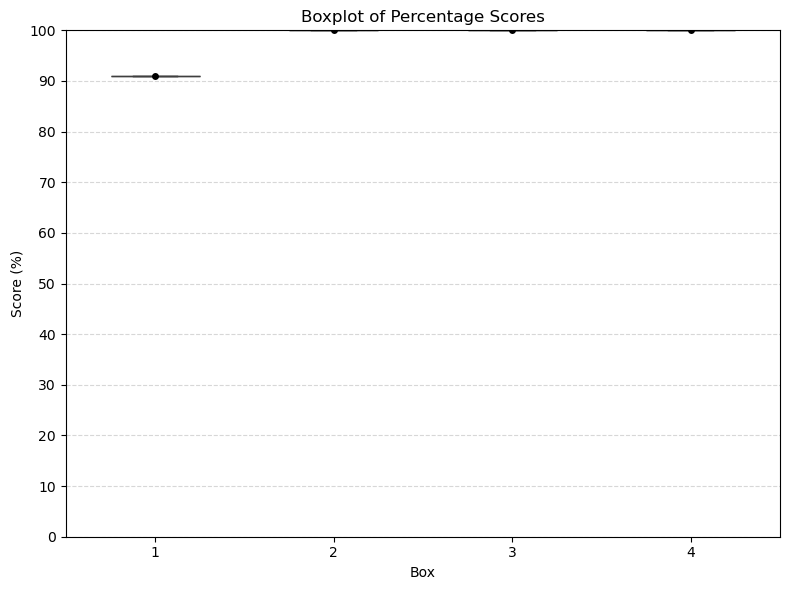

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = pd.DataFrame(precision_1)
# Step 3: Remove % and convert to float
df = df.applymap(lambda x: float(str(x).replace('%', '')))

# Step 4: Convert to long format for seaborn
df_long = df.melt(var_name='Box', value_name='Score')

# Step 5: Plot
plt.figure(figsize=(8, 6))
sns.boxplot(x='Box', y='Score', data=df_long, width=0.5, showfliers=False)
sns.stripplot(x='Box', y='Score', data=df_long, color='black', size=5, jitter=True)

plt.ylim(0, 100)
plt.yticks(range(0, 101, 10))
plt.ylabel("Score (%)")
plt.title("Boxplot of Percentage Scores")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
###300 blocks, 3 times,traditional way


/tmp/ipykernel_2975894/2201896016.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: float(str(x).replace('%', '')))


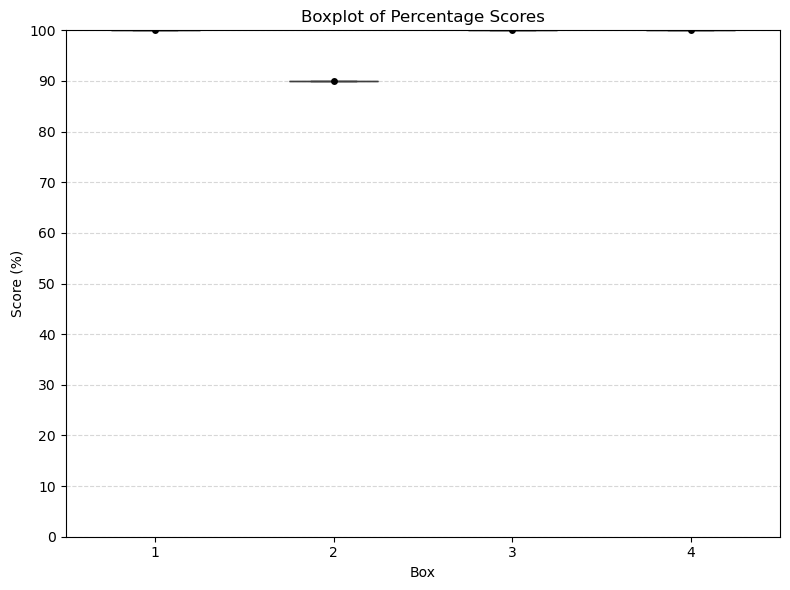

In [24]:
df = pd.DataFrame(recall_1)
# Step 3: Remove % and convert to float
df = df.applymap(lambda x: float(str(x).replace('%', '')))

# Step 4: Convert to long format for seaborn
df_long = df.melt(var_name='Box', value_name='Score')

# Step 5: Plot
plt.figure(figsize=(8, 6))
sns.boxplot(x='Box', y='Score', data=df_long, width=0.5, showfliers=False)
sns.stripplot(x='Box', y='Score', data=df_long, color='black', size=5, jitter=True)

plt.ylim(0, 100)
plt.yticks(range(0, 101, 10))
plt.ylabel("Score (%)")
plt.title("Boxplot of Percentage Scores")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1533272/330304247.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: float(str(x).replace('%', '')))


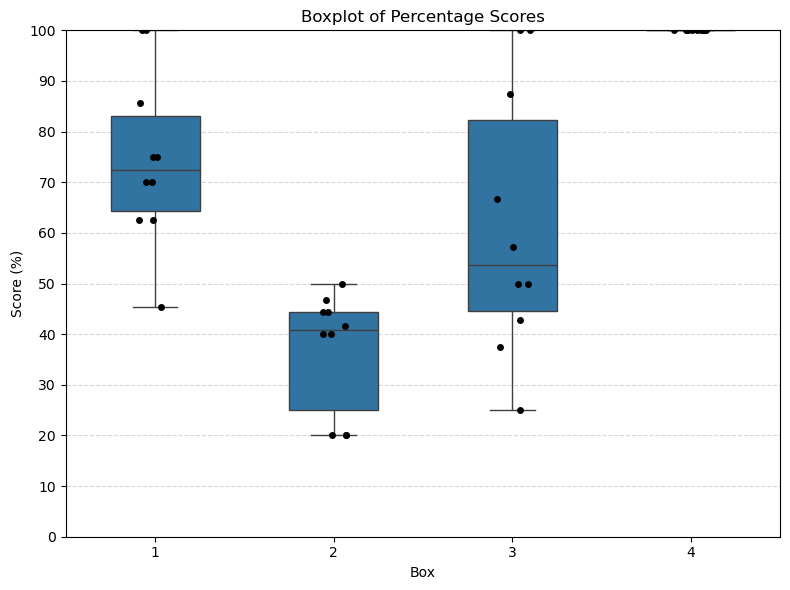

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = pd.DataFrame(precision)
# Step 3: Remove % and convert to float
df = df.applymap(lambda x: float(str(x).replace('%', '')))

# Step 4: Convert to long format for seaborn
df_long = df.melt(var_name='Box', value_name='Score')

# Step 5: Plot
plt.figure(figsize=(8, 6))
sns.boxplot(x='Box', y='Score', data=df_long, width=0.5, showfliers=False)
sns.stripplot(x='Box', y='Score', data=df_long, color='black', size=5, jitter=True)

plt.ylim(0, 100)
plt.yticks(range(0, 101, 10))
plt.ylabel("Score (%)")
plt.title("Boxplot of Percentage Scores")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()